# Statistical Test & Charts
**Project:** Supply Chain Order Fulfillment & Inventory Optimization  
**Phase 7:** Statistical test (ANOVA + Kruskal-Wallis) and 4 charts

**Objective:** Check whether delivery delay really differs between shipping modes, and visualise late deliveries and product revenue.

**Input:** `clean_orders.csv` (Phase 2) &nbsp;|&nbsp; **Output:** 4 PNG charts  
**Validation:** Results are cross-checked with the SQL phases (`05_order_fulfillment.sql`, `06_inventory_analysis.sql`).

# 1. Setup and Load Data
Mount Google Drive, import libraries, and load `clean_orders.csv`. Canceled lines are removed (same rule as in SQL).

In [ ]:
# Connect Google Drive to access the project files
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Project folders (charts folder is created if it does not exist)
data_path = "/content/drive/MyDrive/supply_chain_project/data"
charts_path = "/content/drive/MyDrive/supply_chain_project/charts"
os.makedirs(charts_path, exist_ok=True)

In [ ]:
# Load all orders
df_all = pd.read_csv(f"{data_path}/clean_orders.csv", parse_dates=["order_date", "shipping_date"])
print("all rows:", len(df_all))

# Keep only real orders (remove canceled lines)
df = df_all[df_all["is_canceled"] == 0].copy()
print("rows after removing canceled lines:", len(df))

# Overall late delivery percent
print("late percent:", round(100 * df["is_late"].mean(), 2))

all rows: 180519
rows after removing canceled lines: 176827
late percent: 57.28


**Validation checks**
- Total rows = MySQL row count (180,519). Rows after removing canceled lines = 176,827.
- Late percent (57.28%) = `late_pct` in Step 5.1 of `05_order_fulfillment.sql`.

# 2. Delay Overview by Shipping Mode
**Business question:** Does the delay differ between shipping modes?

`delay_days` = actual shipping days - scheduled days (positive = late).

In [ ]:
# Lines, average delay and spread of delay for each shipping mode
summary = df.groupby("shipping_mode")["delay_days"].agg(["count", "mean", "std"]).round(2)

# Late percent for each shipping mode
summary["late_pct"] = (100 * df.groupby("shipping_mode")["is_late"].mean()).round(2)
print(summary)

                 count  mean   std  late_pct
shipping_mode                               
First Class      27199  1.00  0.00    100.00
Same Day          9512  0.48  0.50     47.90
Second Class     34555  1.99  1.41     79.82
Standard Class  105561 -0.01  1.42     39.75


**Note:** First Class has `std = 0.00`: every line is exactly 1 day late, so its delay does not vary at all.

**Assumption:** each order line is one observation. Lines of the same order are not fully independent, so p-values are a guide, not proof.

In [ ]:
# How many lines have each delay value
print(df["delay_days"].value_counts().sort_index())

# Skewness close to 0 = roughly symmetric
print("skewness:", round(df["delay_days"].skew(), 2))

delay_days
-2    21277
-1    21240
 0    33017
 1    59328
 2    28195
 3     6929
 4     6841
Name: count, dtype: int64
skewness: 0.03


**Result:** `delay_days` has only a few whole-number values (-2 to 4), so it is not a smooth bell curve. Kruskal-Wallis is used as a back-up test.

# 3. ANOVA
**Question:** Are the average delays of the shipping modes different?
- **Null hypothesis:** all shipping modes have the same average delay.
- **p-value:** chance of seeing such a difference if the null hypothesis were true. Below 0.05 = unlikely to be luck.
- With ~177,000 rows even a tiny difference gives a tiny p-value, so the **effect size** is also measured.

In [ ]:
# Delay values of each shipping mode
groups = [g["delay_days"].values for _, g in df.groupby("shipping_mode")]
names = [name for name, _ in df.groupby("shipping_mode")]
print("groups:", names)

# One-way ANOVA
f_value, p_anova = stats.f_oneway(*groups)
print("F =", round(f_value, 2))
print("p-value =", p_anova)

groups: ['First Class', 'Same Day', 'Second Class', 'Standard Class']
F = 22848.34
p-value = 0.0


In [ ]:
# Effect size (eta squared) = share of delay differences explained by shipping mode
grand_mean = df["delay_days"].mean()
# Variation between groups
ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
# Total variation
ss_total = ((df["delay_days"] - grand_mean) ** 2).sum()
# Eta squared
eta_squared = ss_between / ss_total
print("eta squared =", round(eta_squared, 4))

eta squared = 0.2794


**Effect size (eta squared):** share of the delay differences explained by shipping mode (0 = none, 1 = all).  
Rule of thumb: 0.01 small, 0.06 medium, 0.14 or more large.

# 4. Kruskal-Wallis (Back-up Test)
Compares groups using ranks instead of averages, so it does not need a bell curve. If both tests agree, the conclusion is stronger.

In [ ]:
# Kruskal-Wallis test
h_value, p_kw = stats.kruskal(*groups)
n = len(df)
k = len(groups)

# Effect size based on H (same 0.01 / 0.06 / 0.14 rule of thumb)
epsilon_like = (h_value - k + 1) / (n - k)

print("H =", round(h_value, 2))
print("p-value =", p_kw)
print("effect size (eta squared based on H) =", round(epsilon_like, 4))

H = 40944.79
p-value = 0.0
effect size (eta squared based on H) = 0.2315


**Result:** both tests give a very small p-value and a large effect size, so they agree.

# 5. Which Modes Differ?
No extra pair-wise tests are run (many tests increase the chance of false alarms). The average delay per mode (Section 2) and Chart 1 show the differences.

**Note:** the promised days are fixed per mode (First Class 1 day, Second Class 2, Same Day 0, Standard 4). Late percent therefore shows how realistic each promise is, not which carrier is better.

# 6. Summary of Results
| Item | Result |
|---|---|
| Question | Does the delay differ by shipping mode? |
| Tests used | ANOVA, backed up by Kruskal-Wallis (delay is not bell-shaped) |
| ANOVA | F = 22,848.34, p < 0.001 |
| Kruskal-Wallis | H = 40,944.79, p < 0.001 |
| Effect size | Eta squared = 0.28 (ANOVA) and 0.23 (Kruskal-Wallis): **large** |

**Conclusion:** Shipping mode explains about 23-28% of the differences in delay. The difference is statistically real and large in size.

**Limitations:** lines of the same order are not fully independent; First Class has zero variance (ANOVA assumes similar spread in all groups, which is why Kruskal-Wallis is also reported); the result shows association, not cause. Part of the effect is built into the data, because `delay_days` is measured against a promise that is fixed per mode.

# 7. Chart 1: Late Percent by Shipping Mode
**Business question:** Which shipping mode is late most often?  


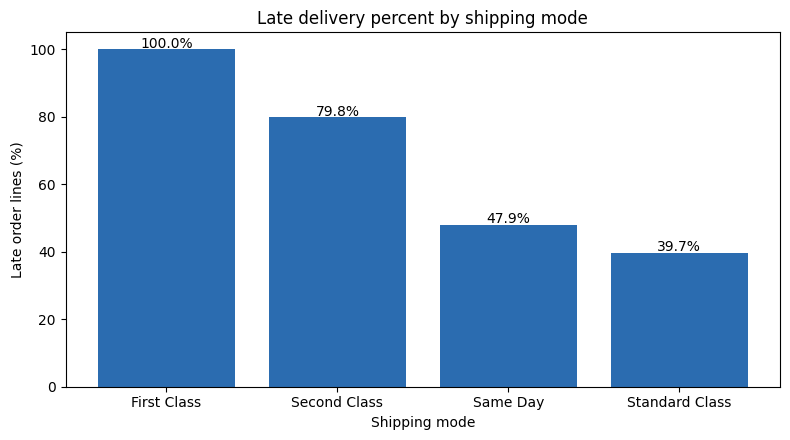

In [ ]:
# Late percent per shipping mode (highest first)
mode_late = (100 * df.groupby("shipping_mode")["is_late"].mean()).sort_values(ascending=False)

# Bar chart
plt.figure(figsize=(8, 4.5))
plt.bar(mode_late.index, mode_late.values, color="#2b6cb0")
plt.title("Late delivery percent by shipping mode")
plt.ylabel("Late order lines (%)")
plt.xlabel("Shipping mode")

# Show the percent on top of each bar
for i, v in enumerate(mode_late.values):
    plt.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.tight_layout()

# Save the chart as PNG
plt.savefig(f"{charts_path}/chart1_late_by_shipping_mode.png", dpi=150)
plt.show()

# 8. Chart 2: Late Percent by Region
**Business question:** Which regions are late most often?  

 Only regions with at least 500 lines are shown, so small groups do not mislead.

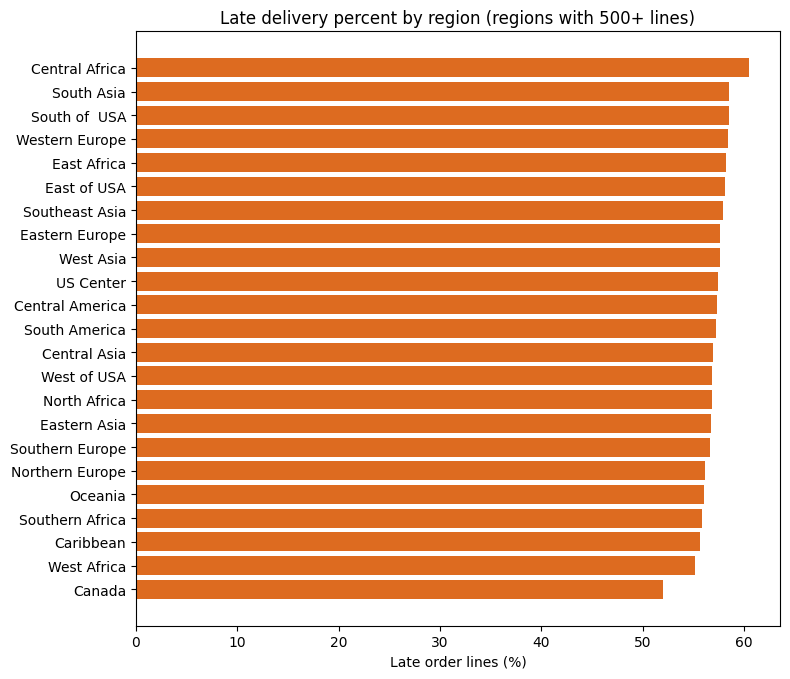

In [ ]:
# Line count and late rate per region
reg = df.groupby("order_region")["is_late"].agg(["count", "mean"])
reg = reg[reg["count"] >= 500].copy()
reg["late_pct"] = 100 * reg["mean"]
reg = reg.sort_values("late_pct")

# Horizontal bar chart
plt.figure(figsize=(8, max(4, 0.3 * len(reg))))
plt.barh(reg.index, reg["late_pct"], color="#dd6b20")
plt.title("Late delivery percent by region (regions with 500+ lines)")
plt.xlabel("Late order lines (%)")
plt.tight_layout()

# Save the chart as PNG
plt.savefig(f"{charts_path}/chart2_late_by_region.png", dpi=150)
plt.show()

**Result:** the regions look alike (about 57%), so location does not explain lateness. Shipping mode (Chart 1) does. All regions have more than 500 lines, so the filter removes none.

# 9. Chart 3: Late Percent by Month
**Business question:** Is lateness improving, getting worse, or seasonal?  
Months with fewer than 200 lines are removed because small months swing too much.

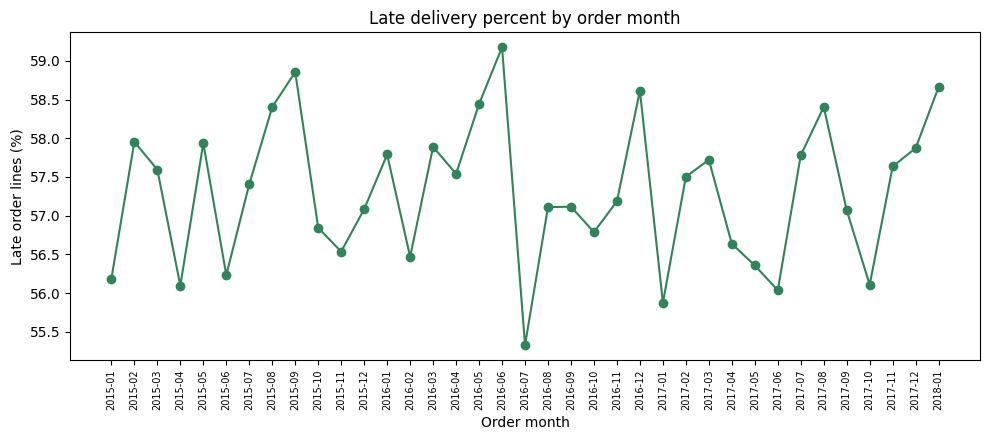

In [ ]:
# Month of each order
df["order_month"] = df["order_date"].dt.to_period("M").astype(str)
month = df.groupby("order_month")["is_late"].agg(["count", "mean"])
month = month[month["count"] >= 200].copy()
month["late_pct"] = 100 * month["mean"]

# Line chart
plt.figure(figsize=(10, 4.5))
plt.plot(month.index, month["late_pct"], marker="o", color="#2f855a")
plt.title("Late delivery percent by order month")
plt.ylabel("Late order lines (%)")
plt.xlabel("Order month")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()

# Save the chart as PNG
plt.savefig(f"{charts_path}/chart3_late_by_month.png", dpi=150)
plt.show()

**Result:** the line is flat, so lateness is steady over time. Order volume drops about 60% from Oct 2017 and 2018 has only January, so those months rest on fewer lines.

# 10. Chart 4: ABC (Pareto) Curve
**Business question:** How few products carry most of the revenue?  
Products are ranked by revenue. The line shows the running total; the 80% and 95% lines mark the A / B / C cut-offs.

abc_class
A     8
B    16
C    94
Name: count, dtype: int64


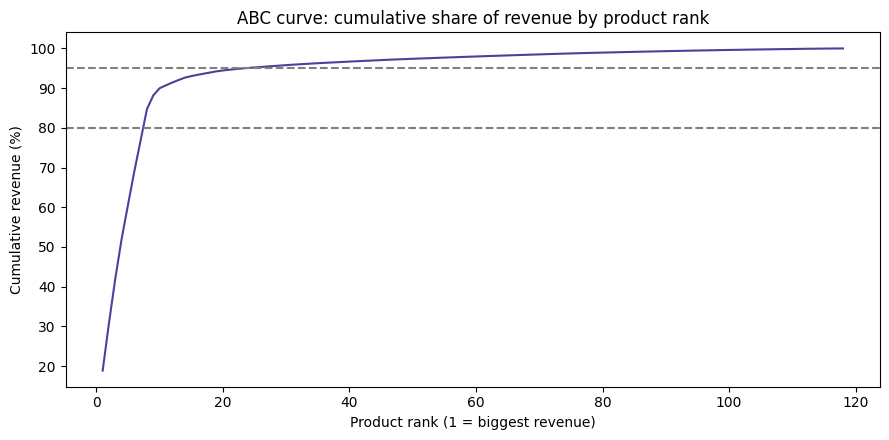

In [ ]:
# Revenue per product (highest first)
prod = df.groupby("product_card_id")["sales"].sum().sort_values(ascending=False).reset_index()
# Running total of revenue in percent
prod["cum_pct"] = 100 * prod["sales"].cumsum() / prod["sales"].sum()
# Share of revenue before each product
before = prod["cum_pct"] - 100 * prod["sales"] / prod["sales"].sum()
# A = first 80%, B = next 15%, C = last 5%
prod["abc_class"] = np.where(before < 80, "A", np.where(before < 95, "B", "C"))
print(prod["abc_class"].value_counts().sort_index())

# Pareto curve
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, len(prod) + 1), prod["cum_pct"], color="#553c9a")
plt.axhline(80, color="grey", linestyle="--")
plt.axhline(95, color="grey", linestyle="--")
plt.title("ABC curve: cumulative share of revenue by product rank")
plt.xlabel("Product rank (1 = biggest revenue)")
plt.ylabel("Cumulative revenue (%)")
plt.tight_layout()

# Save the chart as PNG
plt.savefig(f"{charts_path}/chart4_abc_curve.png", dpi=150)
plt.show()

**Result:** A = 8, B = 16, C = 94 products, matching Step 6.3 in `06_inventory_analysis.sql`. The 8 A products carry about 85% of revenue (the rule includes the product that crosses 80%).

# 11. Check Saved Charts
Confirm the 4 PNG files are saved in the `charts` folder.

In [ ]:
# List the saved chart files
for f in sorted(os.listdir(charts_path)):
    print(f)

chart1_late_by_shipping_mode.png
chart2_late_by_region.png
chart3_late_by_month.png
chart4_abc_curve.png
